# Aegis Project
### Stock Market Financial Stability Study

Downloading and extracting `company_tickers.json` and ZIP archives from www.sec.gov.

In [27]:
import re
import zipfile
from pathlib import Path
import requests
from bs4 import BeautifulSoup
import pandas as pd

# SEC EDGAR requires a custom User-Agent header
HEADERS = {
    "User-Agent": "ScriptPythonData chabot.arthur35@gmail.com",
    "Accept-Encoding": "gzip, deflate",
}
DATA_DIR = Path("./data_sec")


def get_sec_urls():
    """Scrape SEC page for quarterly financial statement ZIP URLs (2010+)."""
    url = "https://www.sec.gov/dera/data/financial-statement-data-sets.html"
    response = requests.get(url, headers=HEADERS, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    urls = []

    for a in soup.find_all("a", href=True):
        href = a["href"]
        match = re.search(r"(20\d{2})q[1-4]\.zip$", href.lower())
        if match and int(match.group(1)) >= 2010:
            full_url = f"https://www.sec.gov{href}" if href.startswith("/") else href
            if full_url not in urls:
                urls.append(full_url)

    print(f"Found {len(urls)} SEC archives (2010+).")
    return urls


def download_and_convert(urls):
    """Download each quarterly ZIP and convert its TXT tables directly to Parquet."""
    for i, url in enumerate(urls, 1):
        zip_path = DATA_DIR / Path(url).name
        quarter_dir = DATA_DIR / zip_path.stem
        quarter_dir.mkdir(parents=True, exist_ok=True)

        print(f"[{i}/{len(urls)}] Processing {zip_path.name}...")
        try:
            with requests.get(url, headers=HEADERS, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(zip_path, "wb") as f:
                    for chunk in r.iter_content(chunk_size=65536):
                        f.write(chunk)

            with zipfile.ZipFile(zip_path, "r") as archive:
                for member in archive.namelist():
                    if member.lower().endswith(".txt"):
                        parquet_path = quarter_dir / Path(member).with_suffix(".parquet").name
                        if not parquet_path.exists():
                            with archive.open(member) as txt_file:
                                df = pd.read_csv(txt_file, sep="\t", low_memory=False, on_bad_lines="skip")
                                df.to_parquet(parquet_path, engine="pyarrow")
            zip_path.unlink()
        except Exception as err:
            print(f"Failed on {zip_path.name}: {err}")


if (DATA_DIR / "2010q1").is_dir():
    print("SEC dataset already exists. Skipping download.")
else:
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    # Download CIK-to-Ticker mapping
    resp = requests.get("https://www.sec.gov/files/company_tickers.json", headers=HEADERS, timeout=60)
    resp.raise_for_status()
    (DATA_DIR / "company_tickers.json").write_text(resp.text, encoding="utf-8")

    sec_urls = get_sec_urls()
    download_and_convert(sec_urls)
    print("Done.")

Found 67 SEC archives (2010+).
[1/67] Processing 2026q3.zip...
[2/67] Processing 2026q2.zip...
[3/67] Processing 2026q1.zip...
[4/67] Processing 2025q4.zip...
[5/67] Processing 2025q3.zip...
[6/67] Processing 2025q2.zip...
[7/67] Processing 2025q1.zip...
[8/67] Processing 2024q4.zip...
[9/67] Processing 2024q3.zip...
[10/67] Processing 2024q2.zip...
[11/67] Processing 2024q1.zip...
[12/67] Processing 2023q4.zip...
[13/67] Processing 2023q3.zip...
[14/67] Processing 2023q2.zip...
[15/67] Processing 2023q1.zip...
[16/67] Processing 2022q4.zip...
[17/67] Processing 2022q3.zip...
[18/67] Processing 2022q2.zip...
[19/67] Processing 2022q1.zip...
[20/67] Processing 2021q4.zip...
[21/67] Processing 2021q3.zip...
[22/67] Processing 2021q2.zip...
[23/67] Processing 2021q1.zip...
[24/67] Processing 2020q4.zip...
[25/67] Processing 2020q3.zip...
[26/67] Processing 2020q2.zip...
[27/67] Processing 2020q1.zip...
[28/67] Processing 2019q4.zip...
[29/67] Processing 2019q3.zip...
[30/67] Processing 20

Using DuckDB to filter and store all 10-K financial records into a single Parquet file.

In [28]:
import time
import duckdb

query = """
WITH filtered AS (
    SELECT 
        s.cik,
        s.name AS company_name,
        s.filed AS filing_date,
        s.adsh,
        n.tag,
        n.value
    FROM read_parquet('data_sec/*/sub.parquet') s
    JOIN read_parquet('data_sec/*/num.parquet') n ON s.adsh = n.adsh
    WHERE s.form = '10-K'
      AND (n.coreg IS NULL OR n.coreg = '') -- parent company only
      AND n.ddate = s.period                -- match reporting period, skip prior years
      AND n.tag IN (
          'Assets', 'Liabilities', 'Revenues', 'SalesRevenueNet',
          'OperatingIncomeLoss', 'NetIncomeLoss',
          'NetCashProvidedByUsedInOperatingActivities'
      )
)
SELECT 
    cik,
    company_name,
    filing_date,
    adsh,
    MAX(CASE WHEN tag = 'Assets' THEN value END) AS Assets,
    MAX(CASE WHEN tag = 'Liabilities' THEN value END) AS Liabilities,
    MAX(CASE WHEN tag IN ('Revenues', 'SalesRevenueNet') THEN value END) AS Revenues,
    MAX(CASE WHEN tag = 'OperatingIncomeLoss' THEN value END) AS OperatingIncome,
    MAX(CASE WHEN tag = 'NetIncomeLoss' THEN value END) AS NetIncome,
    MAX(CASE WHEN tag = 'NetCashProvidedByUsedInOperatingActivities' THEN value END) AS OperatingCash
FROM filtered
GROUP BY cik, company_name, filing_date, adsh
"""

t0 = time.time()
df = duckdb.sql(query).df().dropna()
df.to_parquet("dataset_aegis.parquet")

print(f"Extracted {len(df)} records in {time.time() - t0:.1f}s")
print(df.head())

Extracted 21247 records in 27.9s
        cik               company_name  filing_date                  adsh  \
0    310056  VICON INDUSTRIES INC /NY/     20111222  0000310056-11-000027   
1   1260221        TRANSDIGM GROUP INC     20111118  0001193125-11-316657   
6   1045942          SECUREALERT, INC.     20111229  0001096906-11-003198   
9   1085280         TIBCO SOFTWARE INC     20130128  0001085280-13-000018   
10  1073431     LIFE TECHNOLOGIES CORP     20130228  0001193125-13-080895   

          Assets   Liabilities      Revenues  OperatingIncome    NetIncome  \
0   3.319128e+07  1.074735e+07  4.718224e+07       -9544095.0          0.0   
1   4.513636e+09  3.702687e+09  1.206021e+09      487135000.0  172134000.0   
6   2.268525e+07  9.069941e+06  1.796180e+07       -9451460.0   -9890574.0   
9   1.946908e+09  1.040623e+09  1.024613e+09      177716000.0  122007000.0   
10  8.638065e+09  3.984602e+09  3.798510e+09      665237000.0  430855000.0   

    OperatingCash  
0      -5975544

Joining SEC `cik` numbers with stock `Tickers` since `yfinance` uses tickers to fetch market data.

In [29]:
import json
import pandas as pd

df_sec = pd.read_parquet("dataset_aegis.parquet")

with open("data_sec/company_tickers.json", encoding="utf-8") as f:
    tickers_map = pd.DataFrame.from_dict(json.load(f), orient="index")

tickers_map = tickers_map[["cik_str", "ticker"]].rename(
    columns={"cik_str": "cik", "ticker": "Ticker"}
)
df_merged = df_sec.merge(tickers_map, on="cik", how="inner")
df_merged.to_parquet("dataset_aegis_with_tickers.parquet", index=False)

print(f"Matched {len(df_merged)} filings with valid tickers.")

Matched 12462 filings with valid tickers.


In [30]:
import pandas as pd

df_sec = pd.read_parquet("dataset_aegis_with_tickers.parquet")
print(df_sec.columns.tolist())

['cik', 'company_name', 'filing_date', 'adsh', 'Assets', 'Liabilities', 'Revenues', 'OperatingIncome', 'NetIncome', 'OperatingCash', 'Ticker']


Downloading daily prices with `yfinance` and cleaning the table to remove `NaN` values (delisted companies and non-trading days), keeping ~6.97M rows and 3 columns: `date`, `ticker`, and `close`.

In [31]:
import time
import pandas as pd
import yfinance as yf

df_sec = pd.read_parquet("dataset_aegis_with_tickers.parquet")
df_sec["filing_date"] = pd.to_datetime(
    df_sec["filing_date"].astype(str), format="%Y%m%d", errors="coerce"
)

tickers = df_sec["Ticker"].dropna().astype(str).unique().tolist()
start_date = f"{df_sec['filing_date'].dt.year.min()}-01-01"
end_date = f"{df_sec['filing_date'].dt.year.max() + 2}-01-01"

print(f"Downloading {len(tickers)} tickers ({start_date} to {end_date})...")
raw_prices = yf.download(tickers, start=start_date, end=end_date)

t0 = time.time()
# Convert wide (Price, Ticker) MultiIndex to long format
df_prices = raw_prices.stack(level=1, future_stack=True).reset_index()
df_prices.columns = [str(c).replace(" ", "_").lower() for c in df_prices.columns]

# Keep only valid close prices for target computation
df_prices = df_prices[["date", "ticker", "close"]].dropna(subset=["close"])
df_prices.to_parquet("dataset_aegis_historical_prices.parquet", index=False)

print(f"Saved {len(df_prices)} rows in {time.time() - t0:.1f}s")
print(df_prices.head())

$GGBY: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[***                    7%                       ]  173 of 2371 completed$NCL: possibly delisted; no timezone found
[******                12%                       ]  276 of 2371 completed$DSFT: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[*******               14%                       ]  337 of 2371 completed$SMIO: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[********              16%                       ]  368 of 2371 completed$TVCN: possibly delisted; no timezone found
[**********            20%                       ]  475 of 2371 completed$TCRG: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[*************         27%                       ]  637 of 2371 completed$KPHMW: possibly delisted; no timezone found
[*************         28%                       ]  667 of 2371 completed$AERGP: possibly delisted; no timezone found
[***

Saved 6971400 rows in 3.0s
         date ticker          close
38 2010-01-04   AAME       1.164885
41 2010-01-04   AAPL       6.396101
45 2010-01-04   ABEO    4000.000000
48 2010-01-04   ABUS       4.600000
49 2010-01-04   ABVC  343949.031250


Computing the 1-year Calmar score for each financial report and creating the final ML dataset.

In [32]:
import time
import numpy as np
import pandas as pd
from tqdm import tqdm

df_sec = pd.read_parquet("dataset_aegis_with_tickers.parquet")
df_prices = pd.read_parquet("dataset_aegis_historical_prices.parquet")

df_sec["filing_date"] = pd.to_datetime(
    df_sec["filing_date"].astype(str), format="%Y%m%d", errors="coerce"
)
df_prices["date"] = pd.to_datetime(df_prices["date"])
df_sec = df_sec.dropna(subset=["filing_date"])

# MultiIndex for fast slicing by ticker and date range
df_prices = df_prices.set_index(["ticker", "date"]).sort_index()
df_sec["y_calmar_score__1year"] = np.nan

t0 = time.time()
for idx, row in tqdm(df_sec.iterrows(), total=len(df_sec), desc="Computing Calmar"):
    ticker = row["Ticker"]
    start_dt = row["filing_date"]
    end_dt = start_dt + pd.Timedelta(days=365)

    try:
        prices_1y = df_prices.loc[ticker].loc[start_dt:end_dt, "close"]
        if len(prices_1y) >= 200:  # minimum ~1 trading year
            ret = (prices_1y.iloc[-1] - prices_1y.iloc[0]) / prices_1y.iloc[0]
            peaks = prices_1y.cummax()
            max_dd = ((prices_1y - peaks) / peaks).min()

            df_sec.at[idx, "y_calmar_score__1year"] = ret / max(abs(max_dd), 0.01)
    except KeyError:
        continue

valid_count = df_sec["y_calmar_score__1year"].notna().sum()
print(f"Matched {valid_count}/{len(df_sec)} filings in {time.time() - t0:.1f}s")

df_sec.to_parquet("dataset_aegis_final_ml.parquet")

cols = ["Ticker", "company_name", "filing_date", "y_calmar_score__1year"]
print(df_sec.dropna(subset=["y_calmar_score__1year"])[cols].head())

Computing Calmar: 100%|██████████| 12462/12462 [00:05<00:00, 2215.58it/s]

Matched 10098/12462 filings in 5.6s
  Ticker         company_name filing_date  y_calmar_score__1year
0    TDG  TRANSDIGM GROUP INC  2011-11-18               4.645819
1   TRCK    SECUREALERT, INC.  2011-12-29               0.000000
2    SNA          SNAP-ON INC  2013-02-14               3.635567
3   HLIT         HARMONIC INC  2013-03-01               0.675037
4   EXPO         EXPONENT INC  2013-02-28               2.938987


### 1. Outlier Analysis on the Stability Score

In [33]:
import numpy as np
import pandas as pd

df = pd.read_parquet("dataset_aegis_final_ml.parquet")
scores = df["y_calmar_score__1year"].dropna()

print(f"Valid filings : {len(scores)}")
print(f"Median        : {scores.median():.2f}")
print(f"Mean          : {scores.mean():.2f}")
print(f"Min / Max     : {scores.min():.2f} / {scores.max():.2f}")
print(f"90th / 99th % : {np.percentile(scores, 90):.2f} / {np.percentile(scores, 99):.2f}")

Valid filings : 10098
Median        : 0.09
Mean          : 7.20
Min / Max     : -59.02 / 39999.59
90th / 99th % : 3.45 / 13.31


### 2. Baseline 1: Decision Tree (`max_depth=4`)

In [34]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier

df = pd.read_parquet("dataset_aegis_final_ml.parquet").dropna(subset=["y_calmar_score__1year"])

# Sort chronologically before extracting X and y to prevent look-ahead bias
df = df.sort_values("filing_date").reset_index(drop=True)
df["is_compounder"] = (df["y_calmar_score__1year"] >= 1.0).astype(int)

features = ["Assets", "Liabilities", "Revenues", "OperatingIncome", "NetIncome", "OperatingCash"]
X = df[features].fillna(0)
y = df["is_compounder"]

split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

cutoff = df.loc[split_idx, "filing_date"].date()
print(f"Class balance (%):\n{(y.value_counts(normalize=True) * 100).round(1)}\n")
print(f"Split date: {cutoff} (Train: {len(X_train)}, Test: {len(X_test)})")

dt_model = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)
print(f"\nTest Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred, target_names=["Underperform (0)", "Compounder (1)"]))

Class balance (%):
is_compounder
0    69.9
1    30.1
Name: proportion, dtype: float64

Split date: 2023-03-31 (Train: 8078, Test: 2020)

Test Accuracy: 55.79%
                  precision    recall  f1-score   support

Underperform (0)       0.81      0.52      0.64      1487
  Compounder (1)       0.33      0.66      0.44       533

        accuracy                           0.56      2020
       macro avg       0.57      0.59      0.54      2020
    weighted avg       0.68      0.56      0.58      2020



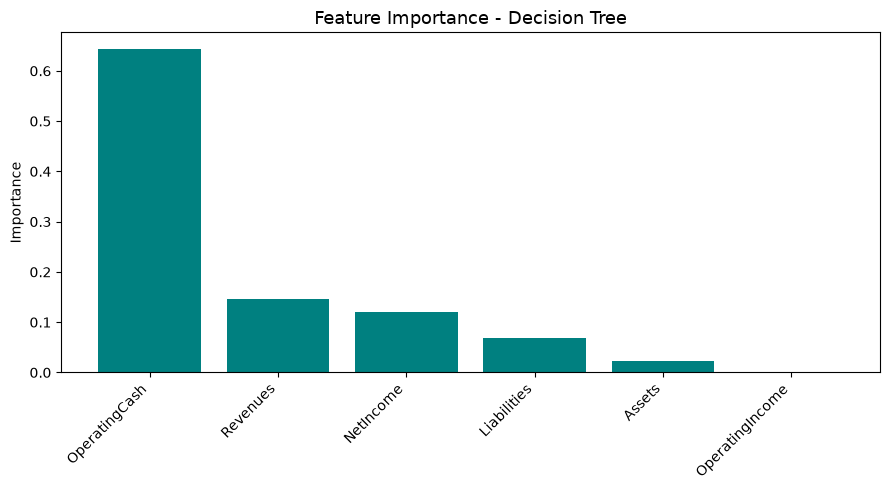

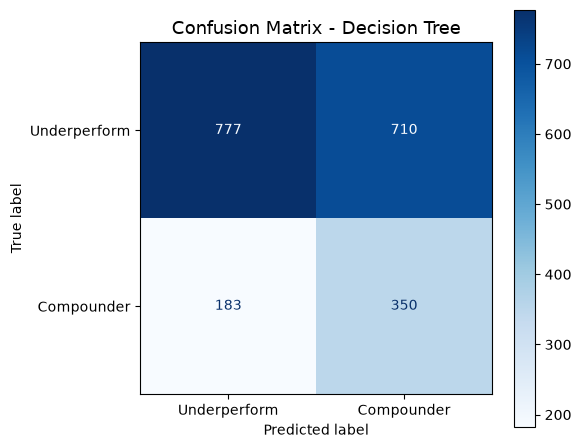

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=features,
    class_names=["Underperform", "Compounder"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10,
)
plt.title("Decision Tree Baseline (Top 3 Levels)", fontsize=14)
plt.savefig("github_arbre_decision.png", dpi=300, bbox_inches="tight")
plt.close()

importances = dt_model.feature_importances_
order = np.argsort(importances)[::-1]

plt.figure(figsize=(9, 5))
plt.bar(range(len(features)), importances[order], color="teal")
plt.xticks(range(len(features)), [features[i] for i in order], rotation=45, ha="right")
plt.title("Feature Importance - Decision Tree", fontsize=13)
plt.ylabel("Importance")
plt.tight_layout()
plt.savefig("github_feature_importance.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    dt_model, X_test, y_test, display_labels=["Underperform", "Compounder"], cmap="Blues", ax=ax
)
plt.title("Confusion Matrix - Decision Tree", fontsize=13)
plt.tight_layout()
plt.show()

### 3. Baseline 2: Random Forest (`100 Trees`, `max_depth=6`)

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf_model.predict(X_train))
test_acc = accuracy_score(y_test, rf_model.predict(X_test))

print(f"Accuracy | Train: {train_acc:.2%} | Test: {test_acc:.2%}\n")
print(classification_report(y_test, rf_model.predict(X_test), target_names=["Underperform (0)", "Compounder (1)"]))

plt.figure(figsize=(22, 10))
plot_tree(
    rf_model.estimators_[0],
    feature_names=features,
    class_names=["Underperform", "Compounder"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
)
plt.title("Random Forest - Sample Tree (Estimator 0)", fontsize=14)
plt.savefig("github_foret_arbre_exemple.png", dpi=300, bbox_inches="tight")
plt.close()

rf_imp = rf_model.feature_importances_
rf_order = np.argsort(rf_imp)[::-1]

plt.figure(figsize=(9, 5))
plt.bar(range(len(features)), rf_imp[rf_order], color="forestgreen")
plt.xticks(range(len(features)), [features[i] for i in rf_order], rotation=45, ha="right")
plt.title("Feature Importance - Random Forest (100 Trees)", fontsize=13)
plt.ylabel("Relative Weight")
plt.tight_layout()
plt.savefig("github_foret_feature_importance.png", dpi=300)
plt.close()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    rf_model, X_test, y_test, display_labels=["Underperform", "Compounder"], cmap="Blues", ax=ax
)
plt.title("Confusion Matrix - Random Forest (Test Set)", fontsize=13)
plt.tight_layout()
plt.savefig("github_foret_matrice_confusion.png", dpi=300)
plt.close()

Accuracy | Train: 59.67% | Test: 61.34%

                  precision    recall  f1-score   support

Underperform (0)       0.80      0.64      0.71      1487
  Compounder (1)       0.35      0.54      0.42       533

        accuracy                           0.61      2020
       macro avg       0.57      0.59      0.57      2020
    weighted avg       0.68      0.61      0.63      2020

